##Business Understanding

Penelitian ini berfokus pada permasalahan gangguan rantai pasok pada proses distribusi ayam hidup di UD Suwara Jaya. Gangguan rantai pasok dapat memengaruhi kelancaran distribusi, efisiensi operasional, dan pemenuhan permintaan pelanggan. Oleh karena itu, penelitian ini bertujuan membangun model prediksi menggunakan algoritma Random Forest untuk mengklasifikasikan kondisi operasional harian ke dalam dua kelas, yaitu gangguan dan tidak gangguan, berdasarkan data historis distribusi.

##Data Understanding

In [ ]:
# =========================
# IMPORT LIBRARY
# =========================

# pandas digunakan untuk membaca dan mengolah data berbentuk tabel
import pandas as pd

# numpy digunakan untuk operasi numerik
import numpy as np

# matplotlib dan seaborn digunakan untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# files digunakan untuk upload file dari laptop ke Google Colab
from google.colab import files

# train_test_split digunakan untuk membagi data menjadi data latih dan data uji
from sklearn.model_selection import train_test_split

# RandomForestClassifier adalah algoritma Random Forest untuk klasifikasi
from sklearn.ensemble import RandomForestClassifier

# metrik evaluasi model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# ===============
# UPLOAD DATASET
# ===============

uploaded = files.upload()

# Mengambil nama file yang diupload
file_name = list(uploaded.keys())[0]

# Membaca file Excel
df = pd.read_excel(file_name)

print("Nama file:", file_name)
print("Ukuran dataset:", df.shape)

# Menampilkan 5 data pertama
display(df.head())

Saving DATASET FINAL.xlsx to DATASET FINAL.xlsx
Nama file: DATASET FINAL.xlsx
Ukuran dataset: (214, 9)


,Tanggal,TotalPengambilan,TotalPesanan,Sisa,Susut,TambahPengambilan,TambahPesanan,suhu_rata_rata,Gangguan
0,2025-04-01,1853.9,1813.5,40.4,0.0,NaN,NaN,28.85,0
1,2025-04-02,1837.3,1477.5,202.0,157.8,NaN,199.0,28.20,1
2,2025-04-03,1521.8,1285.5,211.0,25.3,NaN,NaN,27.45,1
3,2025-04-04,1828.0,1693.5,106.0,28.5,NaN,NaN,28.40,0
4,2025-04-05,1653.0,1479.0,151.5,22.5,NaN,NaN,29.35,0


In [ ]:
# =========================
# CEK NAMA KOLOM
# =========================

print("Daftar kolom dalam dataset:")
print(df.columns.tolist())

Daftar kolom dalam dataset:
['Tanggal', 'TotalPengambilan', 'TotalPesanan', 'Sisa', 'Susut', 'TambahPengambilan', 'TambahPesanan', 'suhu_rata_rata', 'Gangguan']


In [ ]:
# =========================
# INFORMASI DATASET
# =========================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Tanggal            214 non-null    datetime64[ns]
 1   TotalPengambilan   214 non-null    float64       
 2   TotalPesanan       214 non-null    float64       
 3   Sisa               214 non-null    float64       
 4   Susut              214 non-null    float64       
 5   TambahPengambilan  52 non-null     float64       
 6   TambahPesanan      30 non-null     float64       
 7   suhu_rata_rata     214 non-null    float64       
 8   Gangguan           214 non-null    int64         
dtypes: datetime64[ns](1), float64(7), int64(1)
memory usage: 15.2 KB


In [ ]:
# ==================
# CEK MISSING VALUE
# ==================

print("Jumlah missing value tiap kolom:")
print(df.isnull().sum())

Jumlah missing value tiap kolom:
Tanggal                0
TotalPengambilan       0
TotalPesanan           0
Sisa                   0
Susut                  0
TambahPengambilan    162
TambahPesanan        184
suhu_rata_rata         0
Gangguan               0
dtype: int64


In [ ]:
# =========================
# MENGISI MISSING VALUE
# =========================

# Missing value pada kolom tambahan diisi 0
# karena nilai kosong berarti tidak ada tambahan pengambilan/pesanan
df['TambahPengambilan'] = df['TambahPengambilan'].fillna(0)
df['TambahPesanan'] = df['TambahPesanan'].fillna(0)

print("Jumlah missing value setelah diisi 0:")
print(df.isnull().sum())

Jumlah missing value setelah diisi 0:
Tanggal              0
TotalPengambilan     0
TotalPesanan         0
Sisa                 0
Susut                0
TambahPengambilan    0
TambahPesanan        0
suhu_rata_rata       0
Gangguan             0
dtype: int64


In [ ]:
df.head()

,Tanggal,TotalPengambilan,TotalPesanan,Sisa,Susut,TambahPengambilan,TambahPesanan,suhu_rata_rata,Gangguan
0,2025-04-01,1853.9,1813.5,40.4,0.0,0.0,0.0,28.85,0
1,2025-04-02,1837.3,1477.5,202.0,157.8,0.0,199.0,28.20,1
2,2025-04-03,1521.8,1285.5,211.0,25.3,0.0,0.0,27.45,1
3,2025-04-04,1828.0,1693.5,106.0,28.5,0.0,0.0,28.40,0
4,2025-04-05,1653.0,1479.0,151.5,22.5,0.0,0.0,29.35,0


In [ ]:
# ==================
# CEK DATA DUPLIKAT
# ==================

jumlah_duplikat = df.duplicated().sum()

print("Jumlah data duplikat :", jumlah_duplikat)

Jumlah data duplikat : 0


Distribusi label Gangguan:
Gangguan
0    120
1     94
Name: count, dtype: int64


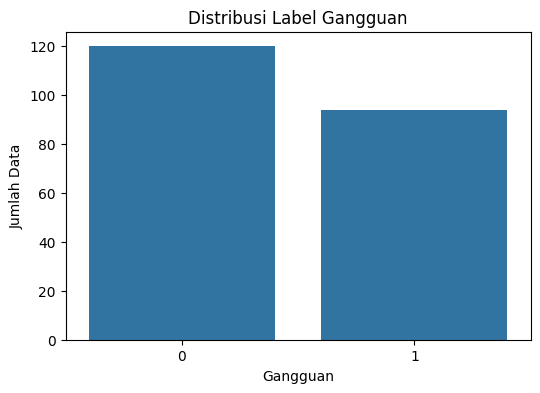

In [ ]:
# =========================
# CEK DISTRIBUSI LABEL
# =========================

print("Distribusi label Gangguan:")
print(df['Gangguan'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Gangguan')
plt.title('Distribusi Label Gangguan')
plt.xlabel('Gangguan')
plt.ylabel('Jumlah Data')
plt.show()

In [ ]:
df.describe()

,Tanggal,TotalPengambilan,TotalPesanan,Sisa,Susut,TambahPengambilan,TambahPesanan,suhu_rata_rata,Gangguan
count,214,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,2025-07-16 12:00:00,1242.956542,1148.752336,75.102336,19.101869,16.671028,18.170561,29.272196,0.439252
min,2025-04-01 00:00:00,684.800000,364.500000,0.000000,-520.500000,0.000000,-29.000000,25.500000,0.000000
25%,2025-05-24 06:00:00,1151.325000,1067.250000,0.000000,7.625000,0.000000,0.000000,28.550000,0.000000
50%,2025-07-16 12:00:00,1223.250000,1137.000000,62.750000,15.600000,0.000000,0.000000,29.250000,0.000000
75%,2025-09-07 18:00:00,1313.375000,1215.000000,117.750000,22.000000,0.000000,0.000000,29.950000,1.000000
max,2025-10-31 00:00:00,1949.500000,1813.500000,735.000000,716.000000,442.500000,770.000000,32.400000,1.000000
std,NaN,168.639987,160.995070,83.499393,114.208790,54.486332,71.670543,1.184093,0.497460


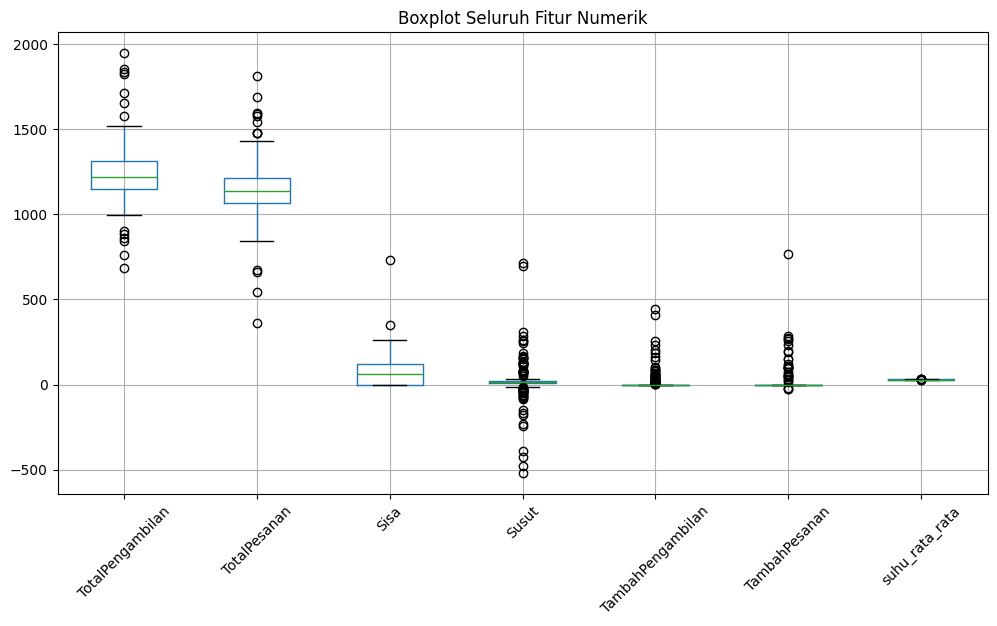

In [ ]:
import matplotlib.pyplot as plt

numeric_features = [
    'TotalPengambilan',
    'TotalPesanan',
    'Sisa',
    'Susut',
    'TambahPengambilan',
    'TambahPesanan',
    'suhu_rata_rata'
]

plt.figure(figsize=(12, 6))
df[numeric_features].boxplot()
plt.title('Boxplot Seluruh Fitur Numerik')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# 2.8 Ringkasan Jumlah Outlier dengan Metode IQR

outlier_summary = []

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    jumlah_outlier = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]

    outlier_summary.append({
        "Fitur": col,
        "Batas Bawah": lower_bound,
        "Batas Atas": upper_bound,
        "Jumlah Outlier": jumlah_outlier
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
display(outlier_summary_df)

,Fitur,Batas Bawah,Batas Atas,Jumlah Outlier
0,TotalPengambilan,908.2500,1556.4500,13
1,TotalPesanan,845.6250,1436.6250,13
2,Sisa,-176.6250,294.3750,2
3,Susut,-13.9375,43.5625,64
4,TambahPengambilan,0.0000,0.0000,52
5,TambahPesanan,0.0000,0.0000,30
6,suhu_rata_rata,26.4500,32.0500,6


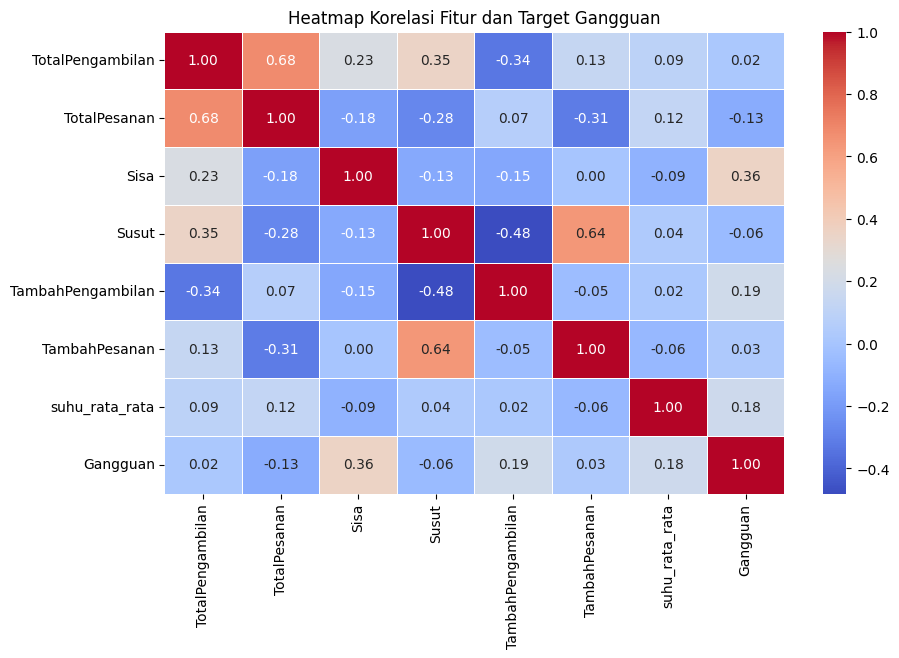

In [ ]:
# =========================
# HEATMAP KORELASI
# =========================

corr_cols = [
    'TotalPengambilan',
    'TotalPesanan',
    'Sisa',
    'Susut',
    'TambahPengambilan',
    'TambahPesanan',
    'suhu_rata_rata',
    'Gangguan'
]

corr_data = df[corr_cols].copy()

for col in corr_cols:
    corr_data[col] = pd.to_numeric(corr_data[col], errors='coerce')

corr_matrix = corr_data.corr(numeric_only=True)

plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Heatmap Korelasi Fitur dan Target Gangguan')
plt.show()

##Data Preparation

In [ ]:
# =========================
# DATA PREPARATION
# =========================

# Menyalin dataset asli agar df tetap aman
data = df.copy()

display(data.head())

,Tanggal,TotalPengambilan,TotalPesanan,Sisa,Susut,TambahPengambilan,TambahPesanan,suhu_rata_rata,Gangguan
0,2025-04-01,1853.9,1813.5,40.4,0.0,0.0,0.0,28.85,0
1,2025-04-02,1837.3,1477.5,202.0,157.8,0.0,199.0,28.20,1
2,2025-04-03,1521.8,1285.5,211.0,25.3,0.0,0.0,27.45,1
3,2025-04-04,1828.0,1693.5,106.0,28.5,0.0,0.0,28.40,0
4,2025-04-05,1653.0,1479.0,151.5,22.5,0.0,0.0,29.35,0


In [ ]:
# Mengubah kolom Tanggal menjadi format datetime
data['Tanggal'] = pd.to_datetime(data['Tanggal'], errors='coerce')

# Memecah Tanggal menjadi 3 kolom numerik
data['Tahun'] = data['Tanggal'].dt.year
data['Bulan'] = data['Tanggal'].dt.month
data['Hari'] = data['Tanggal'].dt.day

display(data[['Tanggal', 'Tahun', 'Bulan', 'Hari']].head())

,Tanggal,Tahun,Bulan,Hari
0,2025-04-01,2025,4,1
1,2025-04-02,2025,4,2
2,2025-04-03,2025,4,3
3,2025-04-04,2025,4,4
4,2025-04-05,2025,4,5


Kolom Tanggal dikonstruksi menjadi Tahun, Bulan, dan Hari agar informasi waktu tetap dapat digunakan dalam model. Hal ini dilakukan karena algoritma Random Forest membutuhkan input dalam bentuk numerik, sedangkan kolom tanggal mentah tidak langsung digunakan sebagai fitur model.

In [ ]:
# Daftar kolom yang seharusnya berbentuk angka
numeric_cols = [
    'TotalPengambilan',
    'TotalPesanan',
    'Sisa',
    'Susut',
    'TambahPengambilan',
    'TambahPesanan',
    'suhu_rata_rata',
    'Gangguan'
]

# Mengubah semua kolom tersebut menjadi numerik
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce')

print(data[numeric_cols].dtypes)

TotalPengambilan     float64
TotalPesanan         float64
Sisa                 float64
Susut                float64
TambahPengambilan    float64
TambahPesanan        float64
suhu_rata_rata       float64
Gangguan               int64
dtype: object


In [ ]:
# Memperbarui total pengambilan dengan tambahan pengambilan
data['TotalPengambilan'] = data['TotalPengambilan'] + data['TambahPengambilan']

# Memperbarui total pesanan dengan tambahan pesanan
data['TotalPesanan'] = data['TotalPesanan'] + data['TambahPesanan']

# Menghitung ulang susut berdasarkan data terbaru
data['Susut'] = data['TotalPengambilan'] - (data['TotalPesanan'] + data['Sisa'])

display(
    data[
        [
            'TotalPengambilan',
            'TotalPesanan',
            'Sisa',
            'Susut',
            'TambahPengambilan',
            'TambahPesanan'
        ]
    ].head(10)
)

,TotalPengambilan,TotalPesanan,Sisa,Susut,TambahPengambilan,TambahPesanan
0,1853.9,1813.5,40.4,0.0,0.0,0.0
1,1837.3,1676.5,202.0,-41.2,0.0,199.0
2,1521.8,1285.5,211.0,25.3,0.0,0.0
3,1828.0,1693.5,106.0,28.5,0.0,0.0
4,1653.0,1479.0,151.5,22.5,0.0,0.0
5,1297.5,1228.0,48.0,21.5,0.0,0.0
6,1351.5,1209.0,120.0,22.5,0.0,0.0
7,1400.0,1306.5,60.0,33.5,0.0,0.0
8,1200.0,1103.0,78.5,18.5,0.0,0.0
9,1120.0,1095.0,0.0,25.0,10.5,0.0


In [ ]:
# Fitur yang digunakan untuk memprediksi Gangguan
feature_cols = [
    'Tahun',
    'Bulan',
    'Hari',
    'TotalPengambilan',
    'TotalPesanan',
    'Sisa',
    'Susut',
    'TambahPengambilan',
    'TambahPesanan',
    'suhu_rata_rata'
]

# Target yang akan diprediksi
target_col = 'Gangguan'

print("Fitur yang digunakan:")
print(feature_cols)

print("\nTarget:")
print(target_col)

Fitur yang digunakan:
['Tahun', 'Bulan', 'Hari', 'TotalPengambilan', 'TotalPesanan', 'Sisa', 'Susut', 'TambahPengambilan', 'TambahPesanan', 'suhu_rata_rata']

Target:
Gangguan


In [ ]:
# Mengambil hanya kolom fitur dan target
model_data = data[feature_cols + [target_col]].dropna().copy()

print("Ukuran dataset siap modeling:", model_data.shape)

display(model_data.head())

Ukuran dataset siap modeling: (214, 11)


,Tahun,Bulan,Hari,TotalPengambilan,TotalPesanan,Sisa,Susut,TambahPengambilan,TambahPesanan,suhu_rata_rata,Gangguan
0,2025,4,1,1853.9,1813.5,40.4,0.0,0.0,0.0,28.85,0
1,2025,4,2,1837.3,1676.5,202.0,-41.2,0.0,199.0,28.20,1
2,2025,4,3,1521.8,1285.5,211.0,25.3,0.0,0.0,27.45,1
3,2025,4,4,1828.0,1693.5,106.0,28.5,0.0,0.0,28.40,0
4,2025,4,5,1653.0,1479.0,151.5,22.5,0.0,0.0,29.35,0


In [ ]:
# X adalah fitur/input
X = model_data[feature_cols]

# y adalah target/output
y = model_data[target_col].astype(int)

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nDistribusi target:")
print(y.value_counts())

Ukuran X: (214, 10)
Ukuran y: (214,)

Distribusi target:
Gangguan
0    120
1     94
Name: count, dtype: int64


##Modelling

In [ ]:
# ===============================
# SPLIT DATA TRAINING DAN TESTING
# ===============================

# Split 80:20
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Split 70:30
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("=== Split 80:20 ===")
print("Data latih:", X_train_80.shape)
print("Data uji  :", X_test_80.shape)

print("\n=== Split 70:30 ===")
print("Data latih:", X_train_70.shape)
print("Data uji  :", X_test_70.shape)

=== Split 80:20 ===
Data latih: (171, 10)
Data uji  : (43, 10)

=== Split 70:30 ===
Data latih: (149, 10)
Data uji  : (65, 10)


In [ ]:
# =========================
# MODEL RANDOM FOREST 80:20
# =========================

rf_80 = RandomForestClassifier(
    n_estimators=100,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42
)

rf_80.fit(X_train_80, y_train_80)

print("Model Random Forest dengan split 80:20 berhasil dilatih.")

Model Random Forest dengan split 80:20 berhasil dilatih.


In [ ]:
# =========================
# MODEL RANDOM FOREST 70:30
# =========================

rf_70 = RandomForestClassifier(
    n_estimators=100,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42
)

rf_70.fit(X_train_70, y_train_70)

print("Model Random Forest dengan split 70:30 berhasil dilatih.")

Model Random Forest dengan split 70:30 berhasil dilatih.


In [ ]:
# =========================
# PREDIKSI DATA UJI
# =========================

y_pred_80 = rf_80.predict(X_test_80)
y_pred_70 = rf_70.predict(X_test_70)

print("Prediksi untuk split 80:20 selesai.")
print("Prediksi untuk split 70:30 selesai.")

Prediksi untuk split 80:20 selesai.
Prediksi untuk split 70:30 selesai.


##Evaluation

In [ ]:
# =========================
# EVALUASI MODEL 80:20
# =========================

acc_80 = accuracy_score(y_test_80, y_pred_80)
prec_80 = precision_score(y_test_80, y_pred_80, zero_division=0)
rec_80 = recall_score(y_test_80, y_pred_80, zero_division=0)
f1_80 = f1_score(y_test_80, y_pred_80, zero_division=0)
cm_80 = confusion_matrix(y_test_80, y_pred_80, labels=[1, 0])

print("=== Evaluasi Random Forest Split 80:20 ===")
print("Accuracy :", round(acc_80, 4))
print("Precision:", round(prec_80, 4))
print("Recall   :", round(rec_80, 4))
print("F1-Score :", round(f1_80, 4))

print("\nConfusion Matrix:")
print(cm_80)

print("\nClassification Report:")
print(classification_report(y_test_80, y_pred_80, zero_division=0))

=== Evaluasi Random Forest Split 80:20 ===
Accuracy : 0.907
Precision: 0.8947
Recall   : 0.8947
F1-Score : 0.8947

Confusion Matrix:
[[17  2]
 [ 2 22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92        24
           1       0.89      0.89      0.89        19

    accuracy                           0.91        43
   macro avg       0.91      0.91      0.91        43
weighted avg       0.91      0.91      0.91        43



In [ ]:
# =========================
# EVALUASI MODEL 70:30
# =========================

acc_70 = accuracy_score(y_test_70, y_pred_70)
prec_70 = precision_score(y_test_70, y_pred_70, zero_division=0)
rec_70 = recall_score(y_test_70, y_pred_70, zero_division=0)
f1_70 = f1_score(y_test_70, y_pred_70, zero_division=0)
cm_70 = confusion_matrix(y_test_70, y_pred_70, labels=[1, 0])

print("=== Evaluasi Random Forest Split 70:30 ===")
print("Accuracy :", round(acc_70, 4))
print("Precision:", round(prec_70, 4))
print("Recall   :", round(rec_70, 4))
print("F1-Score :", round(f1_70, 4))

print("\nConfusion Matrix:")
print(cm_70)

print("\nClassification Report:")
print(classification_report(y_test_70, y_pred_70, zero_division=0))

=== Evaluasi Random Forest Split 70:30 ===
Accuracy : 0.8462
Precision: 0.88
Recall   : 0.7586
F1-Score : 0.8148

Confusion Matrix:
[[22  7]
 [ 3 33]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.92      0.87        36
           1       0.88      0.76      0.81        29

    accuracy                           0.85        65
   macro avg       0.85      0.84      0.84        65
weighted avg       0.85      0.85      0.84        65



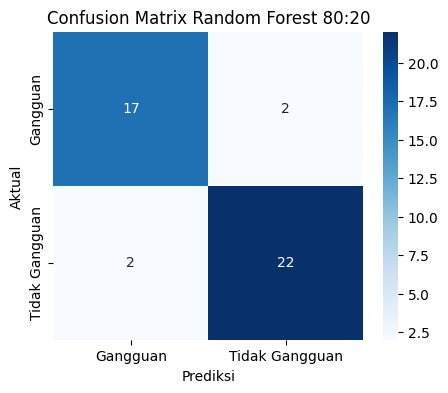

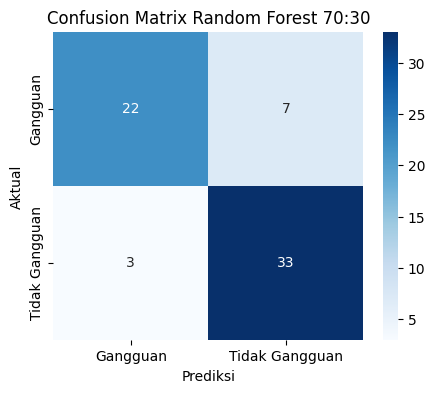

In [ ]:
# =============================
# VISUALISASI CONFUSION MATRIX
# =============================

#RF 80:20
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_80,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Gangguan', 'Tidak Gangguan'],
    yticklabels=['Gangguan', 'Tidak Gangguan']
)

plt.title('Confusion Matrix Random Forest 80:20')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

#RF 70:30
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_70,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Gangguan', 'Tidak Gangguan'],
    yticklabels=['Gangguan', 'Tidak Gangguan']
)

plt.title('Confusion Matrix Random Forest 70:30')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [ ]:
# =========================
# PERBANDINGAN HASIL EVALUASI
# =========================

summary = pd.DataFrame([
    {
        'Skenario': '80:20',
        'Accuracy': acc_80,
        'Precision': prec_80,
        'Recall': rec_80,
        'F1-Score': f1_80
    },
    {
        'Skenario': '70:30',
        'Accuracy': acc_70,
        'Precision': prec_70,
        'Recall': rec_70,
        'F1-Score': f1_70
    }
])

display(summary)

,Skenario,Accuracy,Precision,Recall,F1-Score
0,80:20,0.906977,0.894737,0.894737,0.894737
1,70:30,0.846154,0.880000,0.758621,0.814815


In [ ]:
# =========================
# MENENTUKAN MODEL TERBAIK
# =========================

best_model = summary.loc[summary['F1-Score'].idxmax()]

print("Model terbaik berdasarkan F1-Score:")
print("Skenario :", best_model['Skenario'])
print("Accuracy :", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall   :", round(best_model['Recall'], 4))
print("F1-Score :", round(best_model['F1-Score'], 4))

Model terbaik berdasarkan F1-Score:
Skenario : 80:20
Accuracy : 0.907
Precision: 0.8947
Recall   : 0.8947
F1-Score : 0.8947


In [ ]:
# =========================
# FEATURE IMPORTANCE 80:20
# =========================

feature_importance_80 = pd.DataFrame({
    'Fitur': feature_cols,
    'Importance': rf_80.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(feature_importance_80)

,Fitur,Importance
5,Sisa,0.258747
6,Susut,0.230426
9,suhu_rata_rata,0.179210
4,TotalPesanan,0.098108
3,TotalPengambilan,0.069120
7,TambahPengambilan,0.058923
2,Hari,0.042590
1,Bulan,0.039617
8,TambahPesanan,0.023258
0,Tahun,0.000000


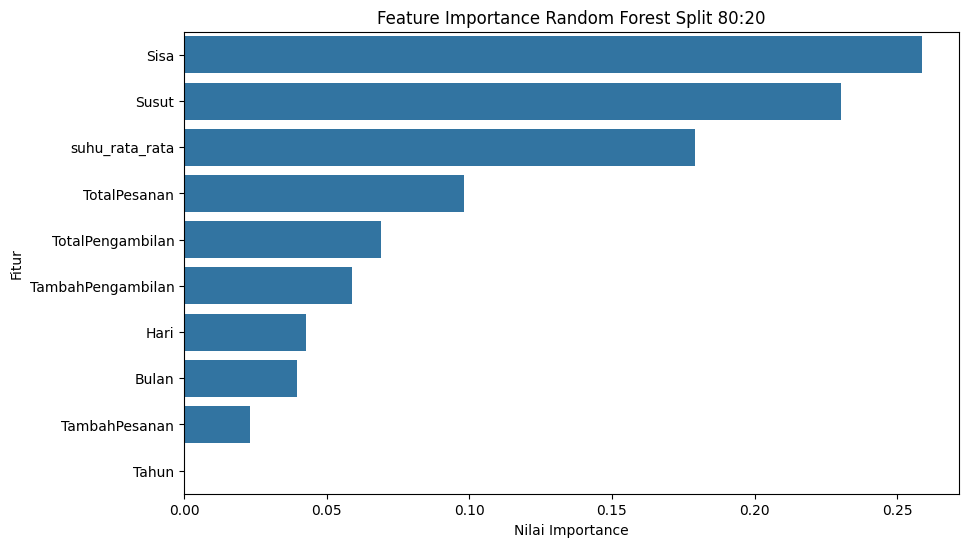

In [ ]:
# =========================
# VISUALISASI FEATURE IMPORTANCE
# =========================

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_80,
    x='Importance',
    y='Fitur'
)

plt.title('Feature Importance Random Forest Split 80:20')
plt.xlabel('Nilai Importance')
plt.ylabel('Fitur')
plt.show()

##Deployment

In [ ]:
# =========================
# DEPLOYMENT
# MENGGUNAKAN MODEL 80:20
# =========================

model_terbaik = rf_80
X_test_terbaik = X_test_80
y_test_terbaik = y_test_80
y_pred_terbaik = y_pred_80
skenario_terbaik = '80:20'

print("Model yang digunakan untuk deployment adalah Random Forest split", skenario_terbaik)

Model yang digunakan untuk deployment adalah Random Forest split 80:20


In [ ]:
# =========================
# MEMBUAT HASIL PREDIKSI
# =========================

hasil_prediksi = X_test_terbaik.copy()

hasil_prediksi['Gangguan_Aktual'] = y_test_terbaik.values
hasil_prediksi['Gangguan_Prediksi'] = y_pred_terbaik

hasil_prediksi['Keterangan_Aktual'] = hasil_prediksi['Gangguan_Aktual'].map({
    0: 'Tidak Gangguan',
    1: 'Gangguan'
})

hasil_prediksi['Keterangan_Prediksi'] = hasil_prediksi['Gangguan_Prediksi'].map({
    0: 'Tidak Gangguan',
    1: 'Gangguan'
})

display(hasil_prediksi.head())

,Tahun,Bulan,Hari,TotalPengambilan,TotalPesanan,Sisa,Susut,TambahPengambilan,TambahPesanan,suhu_rata_rata,Gangguan_Aktual,Gangguan_Prediksi,Keterangan_Aktual,Keterangan_Prediksi
179,2025,9,27,1203.6,1041.5,149.0,13.1,0.0,0.0,32.40,1,1,Gangguan,Gangguan
156,2025,9,4,1254.5,1206.0,33.5,15.0,256.5,0.0,29.50,1,1,Gangguan,Gangguan
168,2025,9,16,1300.8,1222.5,58.0,20.3,0.0,0.0,28.45,0,0,Tidak Gangguan,Tidak Gangguan
68,2025,6,8,1390.7,1203.5,0.0,187.2,231.2,0.0,29.35,1,1,Gangguan,Gangguan
207,2025,10,25,1121.5,1046.0,58.0,17.5,0.0,0.0,26.35,0,0,Tidak Gangguan,Tidak Gangguan


In [ ]:
# =========================
# MENYIMPAN HASIL PREDIKSI
# =========================

hasil_prediksi.to_csv('hasil_prediksi_gangguan_80_20.csv', index=False)
hasil_prediksi.to_excel('hasil_prediksi_gangguan_80_20.xlsx', index=False)

print("File hasil prediksi berhasil disimpan:")
print("- hasil_prediksi_gangguan_80_20.csv")
print("- hasil_prediksi_gangguan_80_20.xlsx")

File hasil prediksi berhasil disimpan:
- hasil_prediksi_gangguan_80_20.csv
- hasil_prediksi_gangguan_80_20.xlsx


In [ ]:
# =========================
# MENYIMPAN MODEL DAN FITUR
# =========================

import joblib

joblib.dump(model_terbaik, 'model_random_forest_gangguan_80_20.pkl')
joblib.dump(feature_cols, 'fitur_model.pkl')

print("Model dan fitur berhasil disimpan:")
print("- model_random_forest_gangguan_80_20.pkl")
print("- fitur_model.pkl")

Model dan fitur berhasil disimpan:
- model_random_forest_gangguan_80_20.pkl
- fitur_model.pkl


In [ ]:
# =========================
# SIMPAN FILE KE GOOGLE DRIVE
# =========================

from google.colab import drive
import os
import shutil

drive.mount('/content/drive')

folder_drive = '/content/drive/MyDrive/SkripsiNew/skripsi_random_forest'
os.makedirs(folder_drive, exist_ok=True)

file_list = [
    'hasil_prediksi_gangguan_80_20.csv',
    'hasil_prediksi_gangguan_80_20.xlsx',
    'model_random_forest_gangguan_80_20.pkl',
    'fitur_model.pkl'
]

for file in file_list:
    shutil.copy(file, folder_drive)

print("Semua file berhasil disimpan ke Google Drive.")
print("Lokasi folder:", folder_drive)

Mounted at /content/drive
Semua file berhasil disimpan ke Google Drive.
Lokasi folder: /content/drive/MyDrive/SkripsiNew/skripsi_random_forest


In [ ]:
# =========================
# INSTALL STREAMLIT DAN NGROK
# =========================

!pip install streamlit pyngrok -q

In [ ]:
# =========================
# SET AUTHTOKEN NGROK
# =========================

from pyngrok import ngrok

NGROK_AUTH_TOKEN = "2qeXlA3MpxQzu0uhbQ7kG7RMP6o_4Xb6mAU4RoNgjS6UUeKff"

ngrok.set_auth_token(NGROK_AUTH_TOKEN)

print("Token ngrok berhasil diset.")

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import os
from datetime import datetime, timedelta

# KONFIGURASI HALAMAN

st.set_page_config(
    page_title="Dashboard Klasifikasi Gangguan Rantai Pasok",
    layout="wide"
)

# LOAD MODEL DAN FITUR

model_path_lokal = "model_random_forest_gangguan_80_20.pkl"
fitur_path_lokal = "fitur_model.pkl"

model_path_drive = "/content/drive/MyDrive/SkripsiNew/skripsi_random_forest/model_random_forest_gangguan_80_20.pkl"
fitur_path_drive = "/content/drive/MyDrive/SkripsiNew/skripsi_random_forest/fitur_model.pkl"

if os.path.exists(model_path_lokal):
    model = joblib.load(model_path_lokal)
elif os.path.exists(model_path_drive):
    model = joblib.load(model_path_drive)
else:
    st.error("File model tidak ditemukan. Pastikan model_random_forest_gangguan_80_20.pkl sudah tersedia.")
    st.stop()

if os.path.exists(fitur_path_lokal):
    feature_cols = joblib.load(fitur_path_lokal)
elif os.path.exists(fitur_path_drive):
    feature_cols = joblib.load(fitur_path_drive)
else:
    st.error("File fitur model tidak ditemukan. Pastikan fitur_model.pkl sudah tersedia.")
    st.stop()

# KONFIGURASI FILE PENYIMPANAN

folder_drive = "/content/drive/MyDrive/SkripsiNew/skripsi_random_forest/dashboard_prediksi"
os.makedirs(folder_drive, exist_ok=True)

file_riwayat_manual = os.path.join(folder_drive, "riwayat_prediksi.csv")

# FUNGSI BANTUAN

def waktu_wib():
    return (datetime.utcnow() + timedelta(hours=7)).strftime("%Y-%m-%d %H:%M:%S") + " WIB"


def baca_file_upload(uploaded_file):
    if uploaded_file.name.endswith(".csv"):
        return pd.read_csv(uploaded_file)
    elif uploaded_file.name.endswith(".xlsx"):
        return pd.read_excel(uploaded_file)
    else:
        return None


def ubah_ke_numeric(series):
    if series.dtype == "object":
        series = series.astype(str).str.replace(",", ".", regex=False)
    return pd.to_numeric(series, errors="coerce")


def siapkan_data_prediksi(data_input):
    data_prediksi = data_input.copy()

    # Membersihkan nama kolom dari spasi
    data_prediksi.columns = data_prediksi.columns.str.strip()

    # Jika ada kolom Gangguan, kolom ini tidak digunakan untuk prediksi
    if "Gangguan" in data_prediksi.columns:
        data_prediksi = data_prediksi.drop(columns=["Gangguan"])

    # Kolom wajib untuk prediksi
    kolom_wajib = [
        "Tanggal",
        "TotalPengambilan",
        "TotalPesanan",
        "Sisa",
        "TambahPengambilan",
        "TambahPesanan",
        "suhu_rata_rata"
    ]

    missing_kolom = [col for col in kolom_wajib if col not in data_prediksi.columns]

    if len(missing_kolom) > 0:
        return None, missing_kolom, data_prediksi

    # Mengubah Tanggal menjadi Tahun, Bulan, Hari
    data_prediksi["Tanggal"] = pd.to_datetime(data_prediksi["Tanggal"], errors="coerce")
    data_prediksi["Tahun"] = data_prediksi["Tanggal"].dt.year
    data_prediksi["Bulan"] = data_prediksi["Tanggal"].dt.month
    data_prediksi["Hari"] = data_prediksi["Tanggal"].dt.day

    # Mengubah kolom numerik utama menjadi angka
    kolom_numerik_awal = [
        "TotalPengambilan",
        "TotalPesanan",
        "Sisa",
        "TambahPengambilan",
        "TambahPesanan",
        "suhu_rata_rata"
    ]

    for col in kolom_numerik_awal:
        data_prediksi[col] = ubah_ke_numeric(data_prediksi[col])

    # Menangani nilai kosong sesuai preprocessing data latih
    # Nilai kosong pada kolom tambahan berarti tidak ada tambahan pengambilan atau pesanan.
    data_prediksi["TambahPengambilan"] = data_prediksi["TambahPengambilan"].fillna(0)
    data_prediksi["TambahPesanan"] = data_prediksi["TambahPesanan"].fillna(0)

    # Simpan nilai awal sebelum dikonstruksi
    total_pengambilan_awal = data_prediksi["TotalPengambilan"].copy()
    total_pesanan_awal = data_prediksi["TotalPesanan"].copy()

    # Konstruksi data matang
    total_pengambilan_akhir = total_pengambilan_awal + data_prediksi["TambahPengambilan"]
    total_pesanan_akhir = total_pesanan_awal + data_prediksi["TambahPesanan"]

    susut_hitung = total_pengambilan_akhir - (total_pesanan_akhir + data_prediksi["Sisa"])

    # Kolom utama langsung diganti dengan data akhir/matang
    data_prediksi["TotalPengambilan"] = total_pengambilan_akhir
    data_prediksi["TotalPesanan"] = total_pesanan_akhir
    data_prediksi["Susut"] = susut_hitung

    # Cek apakah seluruh fitur model tersedia
    missing_fitur_model = [col for col in feature_cols if col not in data_prediksi.columns]

    if len(missing_fitur_model) > 0:
        return None, missing_fitur_model, data_prediksi

    # Mengubah semua fitur model menjadi numerik
    for col in feature_cols:
        data_prediksi[col] = ubah_ke_numeric(data_prediksi[col])

    return data_prediksi, [], data_prediksi


def prediksi_model(data_prediksi):
    X_prediksi = data_prediksi[feature_cols]

    prediksi = model.predict(X_prediksi)
    probabilitas = model.predict_proba(X_prediksi)

    kelas_model = list(model.classes_)

    if 0 in kelas_model:
        prob_tidak_gangguan = probabilitas[:, kelas_model.index(0)]
    else:
        prob_tidak_gangguan = [0] * len(prediksi)

    if 1 in kelas_model:
        prob_gangguan = probabilitas[:, kelas_model.index(1)]
    else:
        prob_gangguan = [0] * len(prediksi)

    return prediksi, prob_tidak_gangguan, prob_gangguan


def buat_tabel_hasil(data_prediksi, prediksi, prob_tidak_gangguan, prob_gangguan):
    hasil = pd.DataFrame()

    hasil["Tanggal"] = data_prediksi["Tanggal"].dt.strftime("%Y-%m-%d")
    hasil["TotalPengambilan"] = data_prediksi["TotalPengambilan"]
    hasil["TotalPesanan"] = data_prediksi["TotalPesanan"]
    hasil["Sisa"] = data_prediksi["Sisa"]
    hasil["Susut"] = data_prediksi["Susut"]
    hasil["TambahPengambilan"] = data_prediksi["TambahPengambilan"]
    hasil["TambahPesanan"] = data_prediksi["TambahPesanan"]
    hasil["Suhu Rata-rata"] = data_prediksi["suhu_rata_rata"]

    hasil["Prediksi_Gangguan"] = prediksi
    hasil["Keterangan_Prediksi"] = hasil["Prediksi_Gangguan"].map({
        0: "Tidak Gangguan",
        1: "Gangguan"
    })

    hasil["Probabilitas_Tidak_Gangguan"] = prob_tidak_gangguan
    hasil["Probabilitas_Gangguan"] = prob_gangguan

    return hasil


# JUDUL DASHBOARD

st.title("Dashboard Klasifikasi Gangguan Rantai Pasok")

st.write(
    "Dashboard ini digunakan untuk mengklasifikasikan apakah data operasional harian "
    "mengalami gangguan rantai pasok atau tidak menggunakan model Random Forest."
)

# MODE PREDIKSI

st.markdown("---")

mode_prediksi = st.radio(
    "Pilih mode prediksi:",
    ["Input Manual Satu Data", "Upload Dataset Baru"],
    horizontal=True
)

# MODE 1: INPUT MANUAL SATU DATA

if mode_prediksi == "Input Manual Satu Data":

    st.subheader("Input Data Operasional Harian")

    with st.form("form_prediksi_manual"):

        col1, col2 = st.columns(2)

        with col1:
            tanggal = st.date_input("Tanggal")

        with col2:
            suhu_rata_rata = st.number_input(
                "Suhu Rata-rata (°C)",
                min_value=0.0,
                step=0.1
            )

        col3, col4 = st.columns(2)

        with col3:
            total_pengambilan = st.number_input(
                "Total Pengambilan (kg)",
                min_value=0.0,
                step=0.1
            )

        with col4:
            total_pesanan = st.number_input(
                "Total Pesanan (kg)",
                min_value=0.0,
                step=0.1
            )

        col5, col6, col7 = st.columns(3)

        with col5:
            sisa = st.number_input(
                "Sisa (kg)",
                min_value=0.0,
                step=0.1
            )

        with col6:
            tambah_pengambilan = st.number_input(
                "Tambah Pengambilan (kg)",
                step=0.1
            )

        with col7:
            tambah_pesanan = st.number_input(
                "Tambah Pesanan (kg)",
                step=0.1
            )

        tombol_prediksi = st.form_submit_button("Klasifikasi dan Simpan Data")

    if tombol_prediksi:

        # Validasi input sederhana
        if (
            total_pengambilan == 0
            and total_pesanan == 0
            and sisa == 0
            and tambah_pengambilan == 0
            and tambah_pesanan == 0
        ):
            st.warning("Mohon isi data operasional terlebih dahulu.")
            st.stop()

        waktu_input_wib = waktu_wib()

        # Menyusun data input awal
        data_input = pd.DataFrame([{
            "Tanggal": str(tanggal),
            "TotalPengambilan": total_pengambilan,
            "TotalPesanan": total_pesanan,
            "Sisa": sisa,
            "TambahPengambilan": tambah_pengambilan,
            "TambahPesanan": tambah_pesanan,
            "suhu_rata_rata": suhu_rata_rata
        }])

        data_prediksi, missing_cols, data_debug = siapkan_data_prediksi(data_input)

        if len(missing_cols) > 0:
            st.error("Terdapat kolom yang belum tersedia.")
            st.write(missing_cols)
            st.stop()

        jumlah_missing = data_prediksi[feature_cols].isnull().sum()

        if jumlah_missing.sum() > 0:
            st.error("Terdapat nilai kosong atau format tidak valid pada fitur model.")
            st.write(jumlah_missing[jumlah_missing > 0])
            st.stop()

        prediksi, prob_tidak_gangguan, prob_gangguan = prediksi_model(data_prediksi)

        hasil_prediksi = buat_tabel_hasil(
            data_prediksi,
            prediksi,
            prob_tidak_gangguan,
            prob_gangguan
        )

        # HASIL PERHITUNGAN DATA

        st.subheader("Hasil Perhitungan Data")

        col1, col2, col3 = st.columns(3)

        with col1:
            st.metric(
                "Total Pengambilan",
                f"{data_prediksi['TotalPengambilan'].iloc[0]:.2f} kg"
            )

        with col2:
            st.metric(
                "Total Pesanan",
                f"{data_prediksi['TotalPesanan'].iloc[0]:.2f} kg"
            )

        with col3:
            st.metric(
                "Susut",
                f"{data_prediksi['Susut'].iloc[0]:.2f} kg"
            )

        # HASIL KLASIFIKASI

        st.subheader("Hasil Klasifikasi")

        keterangan_prediksi = hasil_prediksi["Keterangan_Prediksi"].iloc[0]

        if keterangan_prediksi == "Gangguan":
            st.error("Hasil Klasifikasi: Gangguan")
        else:
            st.success("Hasil Klasifikasi: Tidak Gangguan")

        st.write("Detail hasil klasifikasi:")
        st.dataframe(hasil_prediksi, use_container_width=True)

        # SIMPAN RIWAYAT MANUAL

        hasil_simpan = hasil_prediksi.copy()
        hasil_simpan.insert(0, "Waktu_Input", waktu_input_wib)

        if os.path.exists(file_riwayat_manual):
            data_lama = pd.read_csv(file_riwayat_manual)
            data_baru = pd.concat([data_lama, hasil_simpan], ignore_index=True)
            data_baru.to_csv(file_riwayat_manual, index=False)
        else:
            hasil_simpan.to_csv(file_riwayat_manual, index=False)

        st.success("Data input manual dan hasil klasifikasi berhasil disimpan ke Google Drive.")

        st.write("Lokasi file riwayat:")
        st.code(file_riwayat_manual)

# MODE 2: UPLOAD DATASET BARU

elif mode_prediksi == "Upload Dataset Baru":

    st.subheader("Upload Dataset Baru untuk Klasifikasi Gangguan")

    uploaded_file = st.file_uploader(
        "Upload file CSV atau Excel",
        type=["csv", "xlsx"]
    )

    if uploaded_file is not None:

        data_upload = baca_file_upload(uploaded_file)

        if data_upload is None:
            st.error("Format file tidak didukung. Gunakan CSV atau Excel.")
            st.stop()

        st.write("Preview dataset yang diupload:")
        st.dataframe(data_upload.head(), use_container_width=True)

        tombol_prediksi_file = st.button("Klasifikasi Gangguan")

        if tombol_prediksi_file:

            data_prediksi, missing_cols, data_debug = siapkan_data_prediksi(data_upload)

            if len(missing_cols) > 0:
                st.error("Dataset belum memiliki kolom yang dibutuhkan model.")
                st.write("Kolom yang belum tersedia:")
                st.write(missing_cols)
                st.stop()

            jumlah_missing = data_prediksi[feature_cols].isnull().sum()

            if jumlah_missing.sum() > 0:
                st.error("Terdapat nilai kosong atau format tidak valid pada fitur yang dibutuhkan model.")
                st.write("Jumlah nilai kosong per fitur:")
                st.write(jumlah_missing[jumlah_missing > 0])
                st.stop()

            prediksi_file, prob_tidak_gangguan_file, prob_gangguan_file = prediksi_model(data_prediksi)

            hasil_prediksi = buat_tabel_hasil(
                data_prediksi,
                prediksi_file,
                prob_tidak_gangguan_file,
                prob_gangguan_file
            )

            st.success("Klasifikasi gangguan berhasil dilakukan.")

            # RINGKASAN HASIL KLASIFIKASI

            st.subheader("Ringkasan Hasil Klasifikasi Gangguan")

            jumlah_data = len(hasil_prediksi)
            jumlah_tidak_gangguan = (hasil_prediksi["Prediksi_Gangguan"] == 0).sum()
            jumlah_gangguan = (hasil_prediksi["Prediksi_Gangguan"] == 1).sum()

            col1, col2, col3 = st.columns(3)

            with col1:
                st.metric("Jumlah Data", int(jumlah_data))

            with col2:
                st.metric("Tidak Gangguan", int(jumlah_tidak_gangguan))

            with col3:
                st.metric("Gangguan", int(jumlah_gangguan))

            st.write("Hasil klasifikasi gangguan:")
            st.dataframe(hasil_prediksi, use_container_width=True)

            # SIMPAN HASIL KLASIFIKASI KE GOOGLE DRIVE

            timestamp_file = (datetime.utcnow() + timedelta(hours=7)).strftime("%Y%m%d_%H%M%S")
            file_hasil_prediksi = os.path.join(folder_drive, f"hasil_klasifikasi_gangguan_{timestamp_file}.csv")

            hasil_prediksi.to_csv(file_hasil_prediksi, index=False)

            st.success("Hasil klasifikasi gangguan berhasil disimpan ke Google Drive.")

            st.write("Lokasi file hasil klasifikasi:")
            st.code(file_hasil_prediksi)

            # DOWNLOAD HASIL KLASIFIKASI

            csv_prediksi = hasil_prediksi.to_csv(index=False).encode("utf-8")

            st.download_button(
                label="Download Hasil Klasifikasi Gangguan CSV",
                data=csv_prediksi,
                file_name="hasil_klasifikasi_gangguan.csv",
                mime="text/csv"
            )

# MENAMPILKAN RIWAYAT KLASIFIKASI MANUAL

st.markdown("---")
st.subheader("Riwayat Data Klasifikasi Manual")

if os.path.exists(file_riwayat_manual):
    riwayat = pd.read_csv(file_riwayat_manual)

    st.dataframe(riwayat, use_container_width=True)

    csv_download = riwayat.to_csv(index=False).encode("utf-8")

    st.download_button(
        label="Download Riwayat Klasifikasi Manual CSV",
        data=csv_download,
        file_name="riwayat_klasifikasi_manual.csv",
        mime="text/csv"
    )

else:
    st.info("Belum ada data klasifikasi manual yang tersimpan.")

In [ ]:
# ============================================================
# JALANKAN STREAMLIT + NGROK
# ============================================================

from pyngrok import ngrok

ngrok.kill()

!streamlit run app.py --server.port 8501 &>/content/logs.txt &

public_url = ngrok.connect(8501)
print("Buka aplikasi di URL berikut:")
print(public_url)